# 03 - #FarmersProtest tweets linked to ACLED India

**Data:** `data/tweets/archive.zip` holds 1.08 million tweets with full text (the India farmers' protest, Nov 2020 to Nov 2021). It has no unrest labels. The tweets are linked to ACLED India **by day**: ACLED supplies the ground truth (protests, riots, violent events) for the same dates.

**Prepared by:** `scripts/farmers_prepare.py` (daily tweet table, ACLED daily table, cleaned text file).
**Modelling:** `scripts/farmers_forecast.py` (same-day detection and 1/3/7-day forecasts of ACLED surges) and `scripts/farmers_transfer.py` (does the ACLED-trained DistilRoBERTa work on these tweets?).

**ACLED definitions used:** *farmer-related* = notes mention farm*, or an actor/associated actor mentions Farm/Kisan/SKM. *Violent* = mob violence, violent demonstration, protest with intervention, looting, armed clash, attack. A *surge day* = farmer-related events today at least 2 standard deviations above the previous 28-day mean (and at least 15 events).

In [1]:
import json, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 170)
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FP, RES = ROOT / "data" / "farmers_processed", ROOT / "results"
tw = pd.read_csv(FP / "tweets_daily.csv", parse_dates=["date"]).set_index("date")
ac = pd.read_csv(FP / "acled_daily.csv", parse_dates=["date"]).set_index("date")
d = tw.join(ac)
summ = json.loads((FP / "prepare_summary.json").read_text())
print(f"tweets: {summ['tweets']:,} | days: {summ['days']} ({summ['date_min']} to {summ['date_max']}) | ACLED India events in window: {summ['acled_events_all']:,}, farmer-related: {summ['acled_events_farmer']:,}")
d[["n_tweets", "n_users", "acled_all", "acled_farmer", "acled_farmer_violent", "acled_farmer_riot"]].describe().round(1)

tweets: 1,084,452 | days: 386 (2020-11-01 to 2021-11-21) | ACLED India events in window: 19,679, farmer-related: 5,257


,n_tweets,n_users,acled_all,acled_farmer,acled_farmer_violent,acled_farmer_riot
count,386.0,386.0,386.0,386.0,386.0,386.0
mean,2809.5,1234.6,51.0,13.6,1.3,0.5
std,5861.6,2718.2,38.1,30.2,4.2,1.5
min,5.0,5.0,3.0,0.0,0.0,0.0
25%,1181.5,527.0,30.0,3.0,0.0,0.0
50%,1715.5,670.5,43.0,5.0,0.0,0.0
75%,2821.2,1099.0,60.0,12.0,1.0,0.8
max,83866.0,36693.0,318.0,283.0,55.0,18.0


## 1. Tweet volume and ACLED activity over time

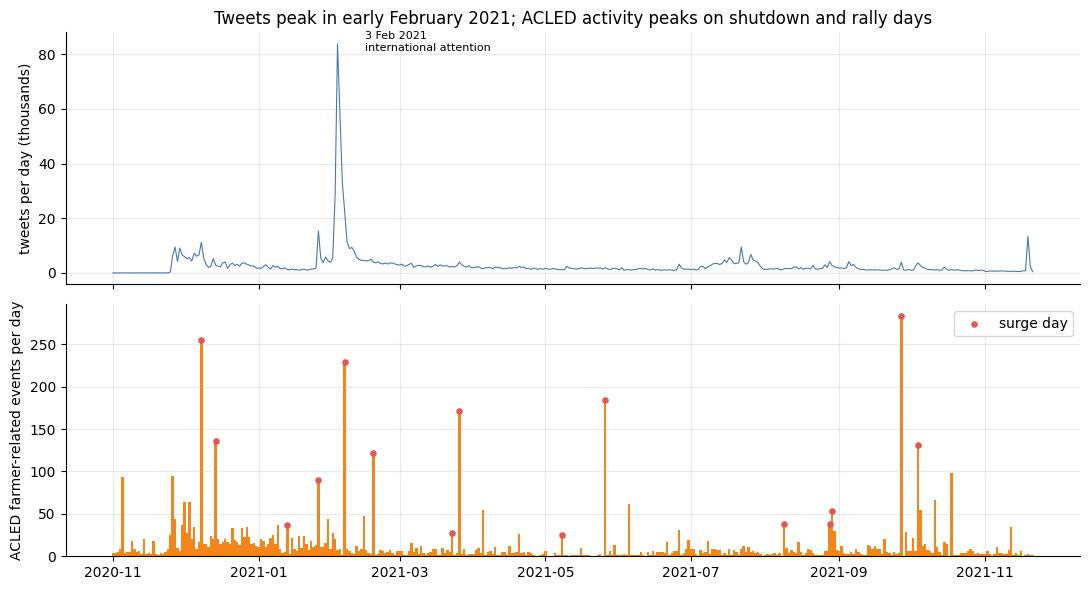

busiest tweet days: {Timestamp('2021-02-03 00:00:00'): 83866, Timestamp('2021-02-04 00:00:00'): 58607, Timestamp('2021-02-05 00:00:00'): 33332, Timestamp('2021-02-02 00:00:00'): 28548, Timestamp('2021-02-06 00:00:00'): 22420}
busiest ACLED farmer days: {Timestamp('2021-09-27 00:00:00'): 283, Timestamp('2020-12-08 00:00:00'): 255, Timestamp('2021-02-06 00:00:00'): 229, Timestamp('2021-05-26 00:00:00'): 184, Timestamp('2021-03-26 00:00:00'): 171}


In [2]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(d.index, d["n_tweets"] / 1e3, lw=0.8, color="#4c78a8"); ax[0].set_ylabel("tweets per day (thousands)")
ax[0].annotate("3 Feb 2021\ninternational attention", (pd.Timestamp("2021-02-03"), d.loc["2021-02-03", "n_tweets"] / 1e3), xytext=(20, -5), textcoords="offset points", fontsize=8)
ax[1].bar(d.index, d["acled_farmer"], width=1.0, color="#f58518"); ax[1].set_ylabel("ACLED farmer-related events per day")
surge_dates = pd.to_datetime(json.loads(Path(sorted(glob.glob(str(RES / "farmers_forecast_*" / "metrics.json")))[-1]).read_text())["surge_days"])
ax[1].scatter(surge_dates, d.loc[surge_dates, "acled_farmer"], color="#e45756", s=14, zorder=3, label="surge day"); ax[1].legend()
ax[0].set_title("Tweets peak in early February 2021; ACLED activity peaks on shutdown and rally days"); plt.tight_layout(); plt.show()
print("busiest tweet days:", d["n_tweets"].nlargest(5).to_dict())
print("busiest ACLED farmer days:", d["acled_farmer"].nlargest(5).to_dict())

## 2. What the tweets talk about

overall share of tweets matching each keyword group (regex lists are in prepare_summary.json):
kw_violence       0.079
kw_police         0.056
kw_event_words    0.035
kw_govt           0.400
kw_intl           0.076
kw_anti           0.044


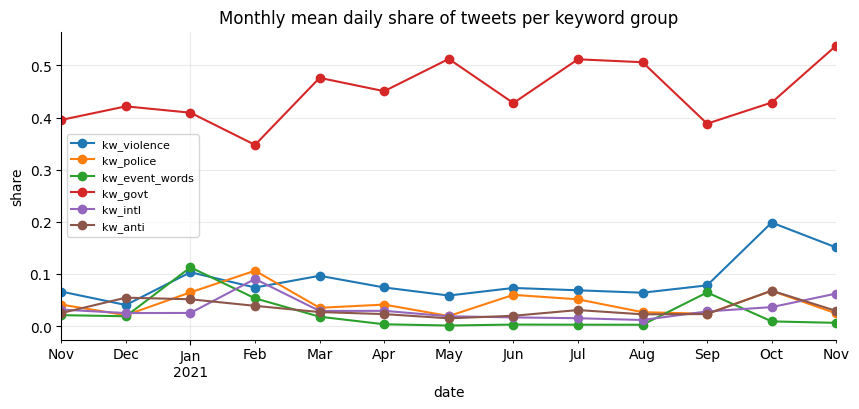

In [3]:
kw = ["kw_violence", "kw_police", "kw_event_words", "kw_govt", "kw_intl", "kw_anti"]
share = d[kw].div(d["n_tweets"], axis=0)
print("overall share of tweets matching each keyword group (regex lists are in prepare_summary.json):")
print((d[kw].sum() / d["n_tweets"].sum()).round(3).to_string())
monthly = share.groupby(share.index.to_period("M")).mean()
monthly.plot(figsize=(10, 4), marker="o"); plt.title("Monthly mean daily share of tweets per keyword group"); plt.ylabel("share"); plt.legend(fontsize=8); plt.show()

## 3. How closely do tweets track ACLED?

same day: Pearson (log) = 0.174, Spearman = 0.289


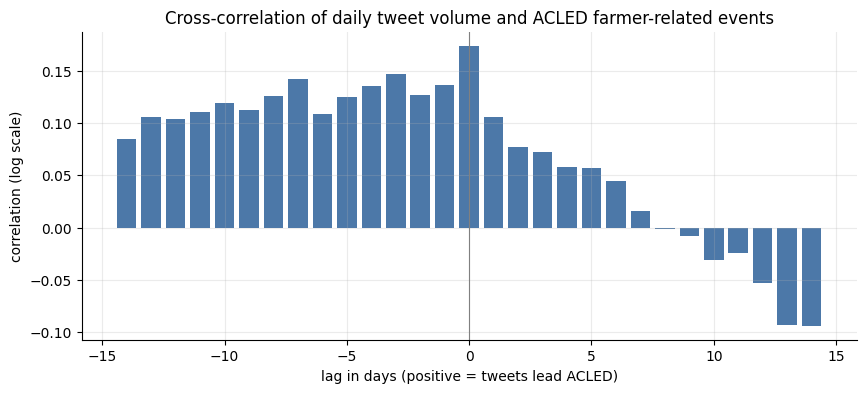

In [4]:
lt, la = np.log1p(d["n_tweets"]), np.log1p(d["acled_farmer"])
print(f"same day: Pearson (log) = {lt.corr(la):.3f}, Spearman = {d['n_tweets'].corr(d['acled_farmer'], method='spearman'):.3f}")
lags = range(-14, 15)
cc = [lt.shift(l).corr(la) for l in lags]
plt.bar(list(lags), cc, color="#4c78a8"); plt.axvline(0, color="grey", lw=0.8)
plt.xlabel("lag in days (positive = tweets lead ACLED)"); plt.ylabel("correlation (log scale)")
plt.title("Cross-correlation of daily tweet volume and ACLED farmer-related events"); plt.show()

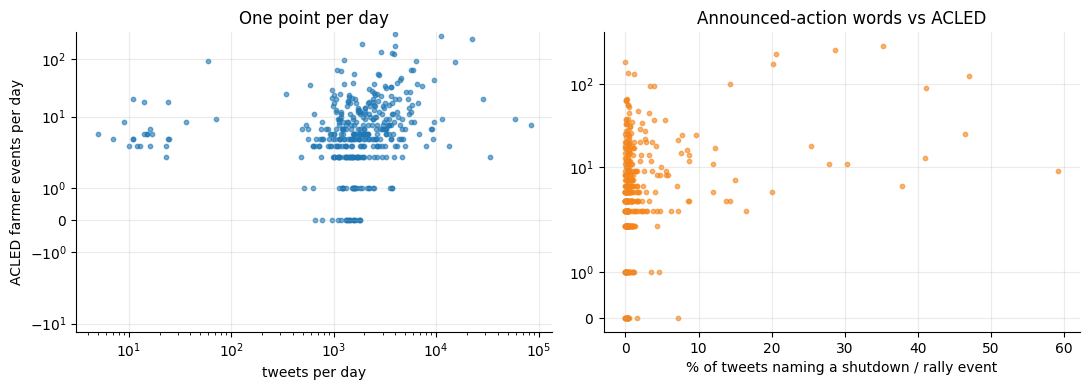

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(d["n_tweets"], d["acled_farmer"], s=10, alpha=0.6); ax[0].set_xscale("log"); ax[0].set_yscale("symlog"); ax[0].set_xlabel("tweets per day"); ax[0].set_ylabel("ACLED farmer events per day")
ax[0].set_title("One point per day")
d["ev_share"] = d["kw_event_words"] / d["n_tweets"]
ax[1].scatter(d["ev_share"] * 100, d["acled_farmer"], s=10, alpha=0.6, color="#f58518"); ax[1].set_yscale("symlog"); ax[1].set_xlabel("% of tweets naming a shutdown / rally event"); ax[1].set_title("Announced-action words vs ACLED")
plt.tight_layout(); plt.show()

## 4. Are surge days visible in the tweets on the same day?

Many of the 15 surge days are announced national actions (Bharat Bandh, chakka jaam, rail roko, the 26 Jan tractor rally). Tweets name these actions on the day itself and often the day before.

In [6]:
fc = sorted(glob.glob(str(RES / "farmers_forecast_*" / "metrics.json")))[-1]
surge = d["acled_farmer"].index.isin(surge_dates).astype(int)
rows = []
for name, s in [("event-word share of tweets", d["ev_share"]), ("event-word tweet count", d["kw_event_words"]), ("log tweet volume", np.log1p(d["n_tweets"])),
                ("violence-word share", d["kw_violence"] / d["n_tweets"]), ("police-word share", d["kw_police"] / d["n_tweets"])]:
    rows.append({"signal (no model, one feature)": name, "ROC-AUC for 'today is a surge day'": round(roc_auc_score(surge, s), 3), "ROC-AUC for 'day before a surge'": round(roc_auc_score(np.r_[surge[1:], 0], s), 3)})
pd.DataFrame(rows)

,"signal (no model, one feature)",ROC-AUC for 'today is a surge day',ROC-AUC for 'day before a surge'
0,event-word share of tweets,0.670,0.663
1,event-word tweet count,0.711,0.712
2,log tweet volume,0.741,0.649
3,violence-word share,0.489,0.485
4,police-word share,0.632,0.527


In [7]:
ctx = []
for s in ["2020-12-08", "2021-01-26", "2021-02-06", "2021-02-18", "2021-03-26", "2021-09-27"]:
    s = pd.Timestamp(s)
    w = d.loc[s - pd.Timedelta(days=3): s + pd.Timedelta(days=1)]
    ctx.append({"surge day": s.date(), "event-word tweets t-3..t+1": w["kw_event_words"].tolist(), "ACLED farmer events t-3..t+1": w["acled_farmer"].tolist()})
pd.DataFrame(ctx)

,surge day,event-word tweets t-3..t+1,ACLED farmer events t-3..t+1
0,2020-12-08,"[161, 289, 812, 3211, 173]","[34, 8, 17, 255, 14]"
1,2021-01-26,"[353, 440, 726, 6308, 1506]","[18, 11, 13, 90, 11]"
2,2021-02-06,"[654, 275, 323, 4606, 155]","[7, 9, 2, 229, 9]"
3,2021-02-18,"[40, 41, 116, 1821, 173]","[7, 4, 3, 122, 1]"
4,2021-03-26,"[8, 19, 222, 797, 89]","[28, 1, 4, 171, 3]"
5,2021-09-27,"[23, 49, 205, 1391, 79]","[5, 3, 4, 283, 0]"


## 5. Forecasting ACLED surges from tweets (walk-forward)

In [8]:
fm = json.loads(Path(sorted(glob.glob(str(RES / "farmers_forecast_*" / "metrics.json")))[-1]).read_text())
rows = []
for h in ("h0", "h1", "h3", "h7"):
    m = fm[h]
    for name, r in m["models"].items():
        ci = m["roc_auc_ci95_block_bootstrap"].get(name)
        rows.append({"task": {"h0": "same day", "h1": "next 1 day", "h3": "next 3 days", "h7": "next 7 days"}[h], "model": name, "base rate": m["base_rate"], "scored days": m["n_scored"], "surges": m["positives"],
                     "ROC-AUC": r["roc_auc"], "ROC-AUC 95% CI": ci, "PR-AUC": r["pr_auc"], "lift": r["pr_auc_lift"]})
res = pd.DataFrame(rows)
res[res["model"] != "prevalence"]

,task,model,base rate,scored days,surges,ROC-AUC,ROC-AUC 95% CI,PR-AUC,lift
1,same day,persistence,0.0336,268,9,0.5465,"[0.345, 0.743]",0.0485,1.44
2,same day,acled,0.0336,268,9,0.5118,"[0.245, 0.764]",0.0408,1.21
3,same day,tweets,0.0336,268,9,0.6319,"[0.434, 0.913]",0.1199,3.57
4,same day,acled_tweets,0.0336,268,9,0.6589,"[0.442, 0.941]",0.2113,6.29
6,next 1 day,persistence,0.0317,252,8,0.5154,"[0.293, 0.724]",0.0472,1.49
7,next 1 day,acled,0.0317,252,8,0.5912,"[0.363, 0.766]",0.0474,1.49
8,next 1 day,tweets,0.0317,252,8,0.5113,"[0.251, 0.807]",0.0400,1.26
9,next 1 day,acled_tweets,0.0317,252,8,0.5543,"[0.33, 0.818]",0.0565,1.78
11,next 3 days,persistence,0.0920,250,23,0.5047,"[0.325, 0.683]",0.1110,1.21
12,next 3 days,acled,0.0920,250,23,0.5413,"[0.366, 0.673]",0.1080,1.17


ROC-AUC difference (ACLED history + tweets) minus (ACLED history only), 95% block-bootstrap interval:
  h0: [0.006, 0.284] <- excludes 0
  h1: [-0.264, 0.259] 
  h3: [-0.243, 0.213] 
  h7: [-0.21, 0.24] 


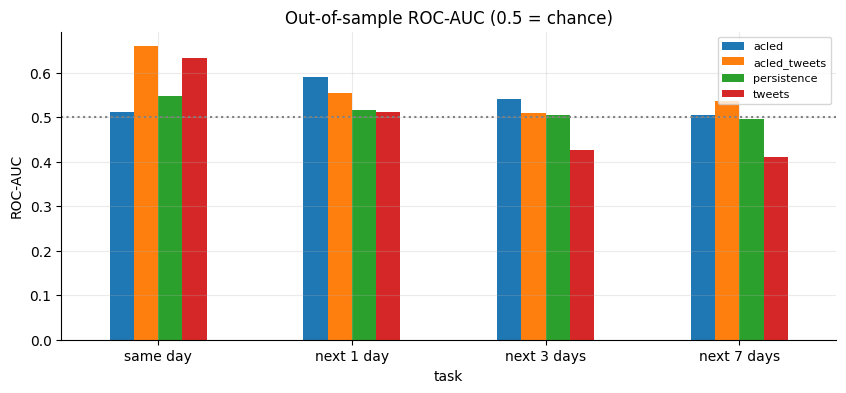

In [9]:
diff = {h: fm[h]["roc_auc_ci95_block_bootstrap"]["diff_acled_tweets_minus_acled"] for h in ("h0", "h1", "h3", "h7")}
print("ROC-AUC difference (ACLED history + tweets) minus (ACLED history only), 95% block-bootstrap interval:")
for h, v in diff.items():
    print(f"  {h}: {v}", "<- excludes 0" if v[0] > 0 else "")
piv = res[res["model"].isin(["persistence", "acled", "tweets", "acled_tweets"])].pivot(index="model", columns="task", values="ROC-AUC")[["same day", "next 1 day", "next 3 days", "next 7 days"]]
piv.T.plot(kind="bar", figsize=(10, 4)); plt.axhline(0.5, color="grey", ls=":"); plt.ylabel("ROC-AUC"); plt.title("Out-of-sample ROC-AUC (0.5 = chance)"); plt.xticks(rotation=0); plt.legend(fontsize=8); plt.show()

## 6. Does the ACLED-trained violence classifier work on these tweets?

In [10]:
tr = sorted(glob.glob(str(RES / "farmers_transfer_*" / "metrics.json")))
if tr:
    run = Path(tr[-1]).parent; tm = json.loads(Path(tr[-1]).read_text())
    print("run:", run.name, "| model:", tm["model"], "| tweets scored:", tm["tweets_scored"], "over", tm["days"], "days")
    print("tweet level:", tm["tweet_level"])
    rows = []
    for name, v in tm["day_level"].items():
        rows.append({"daily signal": name, **{f"{t} (spearman / AUC)": f"{e['spearman']:+.2f} / {e.get('roc_auc_day_has_event', float('nan')):.2f}" for t, e in v.items()}})
    display(pd.DataFrame(rows))
else:
    print("run scripts/farmers_transfer.py first")

run: farmers_transfer_20261118_021926 | model: distilroberta-base_binary_20261117_015913 | tweets scored: 9440 over 386 days
tweet level: {'mean_p': 0.0203, 'share_ge_0.5': 0.0174, 'share_ge_thr': 0.0133, 'quantiles': {'0.5': 0.0002, '0.9': 0.0035, '0.99': 0.9546}}


,daily signal,acled_farmer_violent (spearman / AUC),acled_farmer_riot (spearman / AUC),acled_farmer (spearman / AUC),surge (spearman / AUC)
0,model_mean_p,+0.01 / 0.51,+0.02 / 0.51,-0.04 / 0.36,-0.01 / 0.49
1,model_share_p_ge_0.5,+0.03 / 0.52,+0.05 / 0.53,-0.01 / 0.42,-0.04 / 0.45
2,model_p90,+0.02 / 0.52,+0.04 / 0.53,-0.02 / 0.46,+0.03 / 0.54
3,keyword_violence_share,+0.07 / 0.54,+0.08 / 0.55,+0.10 / 0.49,-0.01 / 0.49
4,tweet_volume,+0.23 / 0.61,+0.19 / 0.62,+0.29 / 0.66,+0.16 / 0.74


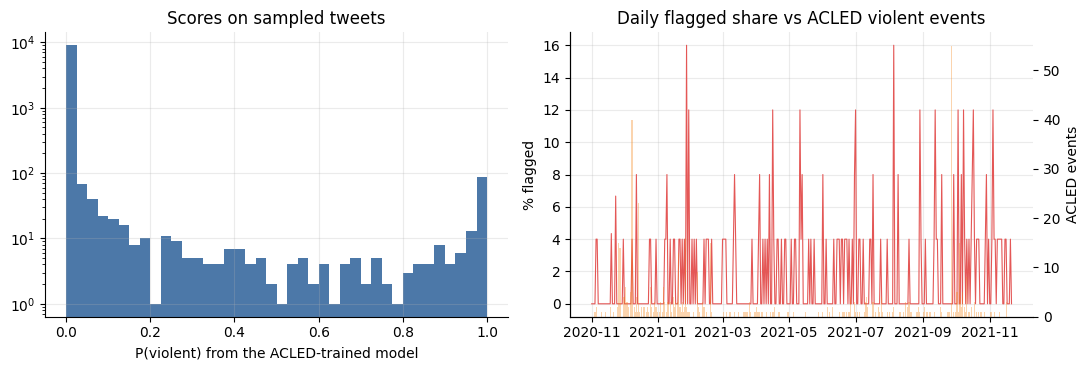

In [11]:
if tr:
    s = pd.read_csv(run / "scores.csv")
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].hist(s["p_violent"], bins=40, color="#4c78a8"); ax[0].set_yscale("log"); ax[0].set_xlabel("P(violent) from the ACLED-trained model"); ax[0].set_title("Scores on sampled tweets")
    dd = pd.read_csv(run / "daily_scores.csv")
    xcol = dd.columns[0]
    ax[1].plot(pd.to_datetime(dd[xcol]), dd["share_p_ge_0.5"] * 100, lw=0.8, color="#e45756", label="% sampled tweets flagged"); ax[1].set_ylabel("% flagged")
    ax2 = ax[1].twinx(); ax2.bar(pd.to_datetime(dd[xcol]), dd["acled_farmer_violent"], width=1.0, alpha=0.35, color="#f58518", label="ACLED farmer violent events"); ax2.set_ylabel("ACLED events"); ax2.grid(False)
    ax[1].set_title("Daily flagged share vs ACLED violent events"); plt.tight_layout(); plt.show()
    top = pd.read_csv(run / "top_tweets.csv")
    pd.set_option("display.max_colwidth", 140)
    top.head(12).assign(text=lambda x: x["text"].str.replace("\n", " ").str[:140])[["day", "p_violent", "text"]]

## 7. Findings and limitations

**Data**
- 1,084,452 tweets with full text from about 165,000 accounts, over 386 days (1 Nov 2020 to 21 Nov 2021). ACLED India has 19,679 events in the same window; 5,257 are farmer-related (507 violent, 186 riots) and 15 days qualify as surges.
- Tweet volume and ACLED activity are only loosely related (same-day Spearman 0.29, log-scale Pearson 0.17). The cross-correlation peaks at lag 0, so tweets neither lead nor lag ACLED on average. The biggest tweet spike (3 Feb 2021, 83,866 tweets, around the international posts) came when ACLED farmer events were low (7 that day); ACLED activity peaked on shutdown days such as 27 Sep 2021 (283 events).

**What the tweets do capture**
- Tweets name announced actions (Bharat Bandh, chakka jaam, rail roko, tractor rally) mostly on the day itself, and often more on the day before. For the 8 Dec 2020 Bharat Bandh, tweets naming an action went 161, 289, 812, 3,211 over the four days up to it.
- With no model, single signals separate surge days from other days: log tweet volume has ROC-AUC 0.74 and the count of action-naming tweets 0.71. Violence words carry no signal (0.49).
- In a walk-forward test (same-day detection), tweets plus ACLED history reach ROC-AUC 0.66, against 0.51 for ACLED history alone; the 95% interval for the difference is [0.006, 0.284]. It only just excludes zero and rests on 9 surge days, so this is suggestive, not conclusive.

**What they do not do**
- Forecasting 1, 3 or 7 days ahead shows no skill. ROC-AUC is 0.43 to 0.59, every interval includes 0.5, and adding tweets did not help.
- The ACLED-trained DistilRoBERTa does not transfer as it stands. It flags 1.7% of 9,440 sampled tweets as violent. In the 12 top-scored tweets I read, about half describe beatings, attacks or injuries and the rest are false alarms (a rain storm, a contract, politics). Its daily flag rate has no relationship with ACLED violent events (Spearman +0.01 to +0.05), which is worse than the keyword baseline (+0.07) and far below plain volume (+0.23). There are no hand labels yet, so there is no precision, recall or F1 for it.

**Limitations**
- One movement in one year, 15 surge days and 9 of them in the scored period. Differences between models are within noise unless an interval excludes zero.
- The archive is a hashtag-based sample (about 2,800 tweets a day). Whether it is representative is unknown, and it cannot say anything about unrest elsewhere in India.
- "Farmer-related" ACLED events and the keyword groups are my own heuristics (listed in `prepare_summary.json` and the script), not an official classification.
- The CSV's tweetId column lost precision, so tweet IDs come from the URLs. Six malformed lines were dropped.
- Next step for real extraction metrics: hand-label `label_sample.csv` (300 tweets) and run `scripts/farmers_transfer_eval.py`, then fine-tune on those labels.